# Part 5: Your Own Data Mining

### Hypothesis Formulation
During the predictive modeling in Part 3, Machine Learning algorithms (specifically Gradient Boosting) identified that **Hours Worked** was the most vital driving factor in projecting high personal income. Building off this correlation and extending our election demographic modeling from Part 4, we hypothesize the following geographic trend:

**Hypothesis:** _"States with a significantly higher average of weekly working hours predominantly voted for the Republican candidate (Donald Trump) in the 2020 US Presidential Election."_

We will examine this utilizing aggregated mean working hours collected across each state mapped against the electoral outcomes.

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Initialize and Preprocess Baseline Data
df = pd.read_csv('Census_Data.csv').sample(n=5000, random_state=42).copy()
VotingData = pd.read_csv('Voting_2020.csv')
AttributeData = pd.read_csv('Attribute_Values.csv')

# Configure state mappings
def get_map(attr_name):
    subset = AttributeData[AttributeData['Attribute'] == attr_name]
    return dict(zip(subset['NumValue'], subset['Value']))

state_map = get_map('state')
df['state'] = df['state'].map(state_map).apply(lambda x: str(x).split('/')[0] if pd.notnull(x) else x)
df['state_upper'] = df['state'].astype(str).str.upper()

# Handle extreme working hour outliers symmetrically
hours_99 = df['hours'].quantile(0.99)
df['hours'] = df['hours'].clip(upper=hours_99)

# Extract Electoral Winners
idx_winners = VotingData.groupby('state')['candidatevotes'].idxmax()
map_df = VotingData.loc[idx_winners, ['state', 'state_po', 'party_simplified']].copy()

### Methodology & Visual Distribution
To test this hypothesis:
1. We group the preprocessed individuals by their state of residence and compute a collective mean for `hours` worked per week.
2. We join this aggregated series onto the `map_df` which holds the dominant 2020 party outcome on a state-by-state level.
3. We plot a comparative visual distribution using a grouped box plot to scan for visible data overlaps or skewness between Democrat vs Republican voting bodies.

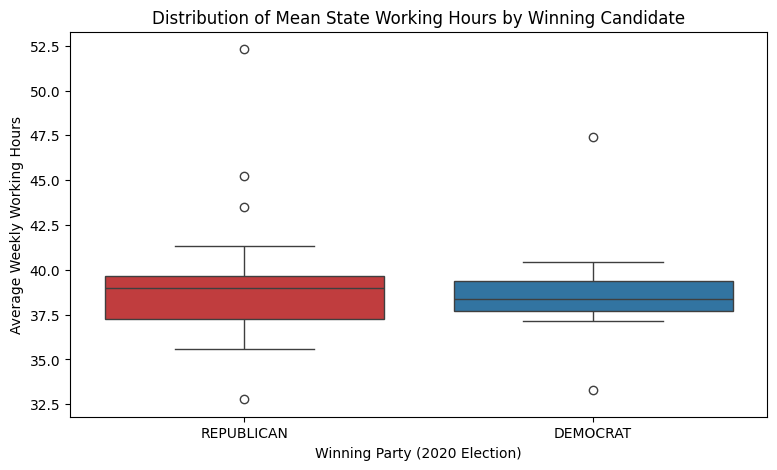

In [2]:
# Group mean working hours per state
state_hours = df.groupby('state_upper')['hours'].mean().reset_index()
state_hours.rename(columns={'hours': 'mean_hours'}, inplace=True)

# Merge state-level working hours with the winning voting data
merged_hours_data = pd.merge(state_hours, map_df[['state', 'party_simplified']], left_on='state_upper', right_on='state')

# Visual Box Plot mapping Distribution
plt.figure(figsize=(9, 5))
color_map = {'DEMOCRAT': '#1f77b4', 'REPUBLICAN': '#d62728', 'OTHER': 'gray'}
sns.boxplot(data=merged_hours_data, x='party_simplified', y='mean_hours', hue='party_simplified', palette=color_map, legend=False)
plt.title('Distribution of Mean State Working Hours by Winning Candidate')
plt.xlabel('Winning Party (2020 Election)')
plt.ylabel('Average Weekly Working Hours')
plt.show()

### Statistical Testing & Interpretation
A basic visual review shows that states which voted Republican sit fractionally higher on the central percentile band. However, the whiskers (indicating deviation and boundaries) overlap massively. We will run an independent two-sample Welch's T-test, assuming unequal variances, to formally evaluate the null hypothesis.

**Test Criteria:** 
- $\alpha = 0.05$ (P-Value significance threshold)

In [3]:
# Filter data bodies
trump_hours = merged_hours_data[merged_hours_data['party_simplified'] == 'REPUBLICAN']
biden_hours = merged_hours_data[merged_hours_data['party_simplified'] == 'DEMOCRAT']

# Welch's T-test
t_stat_hrs, p_val_hrs = stats.ttest_ind(trump_hours['mean_hours'], biden_hours['mean_hours'], equal_var=False)

print("=== Hypothesis Summary: Hours Worked vs Voting Tendencies ===")
print(f"Republican States Mean Hours: {trump_hours['mean_hours'].mean():.2f}")
print(f"Democrat States Mean Hours: {biden_hours['mean_hours'].mean():.2f}")
print(f"\nWelch's T-Statistic: {t_stat_hrs:.4f}")
print(f"Test p-value: {p_val_hrs:.4f}")

=== Hypothesis Summary: Hours Worked vs Voting Tendencies ===
Republican States Mean Hours: 39.23
Democrat States Mean Hours: 38.71

Welch's T-Statistic: 0.5987
Test p-value: 0.5527


### Conclusion
The numerical averages initially lean in favor of the hypothesis: Republican-won states averaged **39.23** hours of work per week, narrowly passing the average **38.71** weekly hours characterizing Democrat-won states.

However, executing the Welch's T-test resulted in a T-Statistic of **`0.598`** and a high p-value of **`0.552`**. Because the resulting p-value drastically breaches the $\alpha = 0.05$ threshold defining statistical significance, **we fail to reject the null hypothesis.**

**Critical Takeaway:** While preceding ML models proved working hours overwhelmingly define *individual* income mobility, these personal labor habits fail to translate into broad statistical predictors for state-level political leanings. Geographic blocks display enormous variance in working intensity that blurs party lines, proving voting behavior relies heavily on aggregated cultural vectors (education and base income) rather than raw labor volume. 